# Noise and Performance Analysis

This notebook investigates how the performance of the machine-learning estimator changes when the Ramsey measurement conditions are varied. We study two important physical parameters:

1. **Number of measurement shots:** more shots reduce the statistical uncertainty in the measured probability.
2. **Coherence time ${(T_2)}$:** a longer coherence time preserves Ramsey-fringe visibility for longer interrogation times.

For each condition, we generate a new simulated dataset, train a Random Forest model and evaluate its magnetic-field estimation error.

The probability of measuring ${(|1\rangle)}$ is ${p_1(B,t)=\frac{1-e^{-t/T_2}\cos(\gamma Bt)}{2}}$. A finite number of shots produces a measured frequency ${\hat p_1 = \frac{n_1}{N}}$ where ${(n_1)}$ is sampled from a binomial distribution with N trials. Increasing N generally reduces the sampling fluctuations in ${\hat p_1}$.

The coherence factor ${e^{-t/T_2}}$ determines the visibility of the Ramsey oscillations. A shorter ${T_2}$ causes faster decay of the signal contrast.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gamma = 2*np.pi*28e9
times = np.array([20, 50, 100, 200, 400]) * 1e-6
Bmin_nT = 0.0
Bmax_nT = 100.0
samples = 2500
randomstate = 42

def ramsey_probability(B_T, t, T2, gamma=gamma):
    visibility = np.exp(-t / T2)
    return 0.5 * (1 - visibility*np.cos(gamma*B_T*t))

def make_dataset(shots, T2, n_samples=samples, seed=randomstate):
    rng = np.random.default_rng(seed)
    B_nT = rng.uniform(Bmin_nT, Bmax_nT, n_samples)
    B_T = B_nT * 1e-9

    p = ramsey_probability(B_T[:, None], times[None, :], T2)
    counts = rng.binomial(shots, p)
    frequencies = counts/shots

    columns = [f"P1_{int(t * 1e6)}us" for t in times]
    frame = pd.DataFrame(frequencies, columns=columns)
    frame["B_nT"] = B_nT
    return frame

def evaluate_random_forest(frame):
    feature_cols = [f"P1_{int(t * 1e6)}us" for t in times]
    X = frame[feature_cols]
    y = frame["B_nT"]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=randomstate)

    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=randomstate, n_jobs=-1)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    return {"MAE": mean_absolute_error(y_test, pred), "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)}

We vary the number of repeated measurements per interrogation time while keeping the coherence time fixed at ${T_2=1}$ ms. The measured probabilities become less noisy as the shot count increases.

In [8]:
shot_values = [50, 100, 200, 500]
shot_results = []

for shots in shot_values:
    frame = make_dataset(shots=shots, T2=1e-3, seed=randomstate + shots)
    metrics = evaluate_random_forest(frame)
    metrics["Shots"] = shots
    shot_results.append(metrics)

shot_results = pd.DataFrame(shot_results)
display(shot_results)

,MAE,RMSE,R2,Shots
0,3.108433,4.218740,0.979402,50
1,2.287009,3.006766,0.988631,100
2,1.653101,2.214147,0.994117,200
3,1.024745,1.372974,0.997796,500


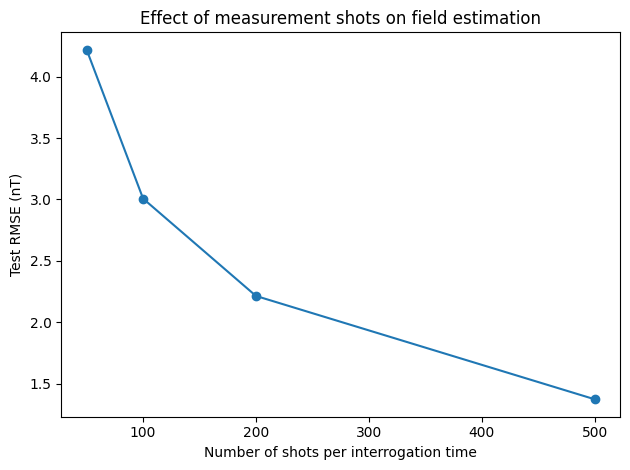

In [9]:
plt.plot(shot_results["Shots"], shot_results["RMSE"], marker="o")
plt.xlabel("Number of shots per interrogation time")
plt.ylabel("Test RMSE (nT)")
plt.title("Effect of measurement shots on field estimation")
plt.tight_layout()
plt.show()

We now vary ${T_2}$ while keeping the number of shots fixed at 200. A longer coherence time maintains a larger signal contrast at a given interrogation time. This can preserve more information about the accumulated magnetic-field phase.

In [10]:
T2_values_ms = [0.25, 0.5, 1.0, 2.0]
T2_results = []

for T2_ms in T2_values_ms:
    frame = make_dataset(shots=200, T2=T2_ms * 1e-3, seed=randomstate + int(T2_ms * 1000))
    metrics = evaluate_random_forest(frame)
    metrics["T2_ms"] = T2_ms
    T2_results.append(metrics)

T2_results = pd.DataFrame(T2_results)
display(T2_results)

,MAE,RMSE,R2,T2_ms
0,3.345449,4.214820,0.980255,0.25
1,2.240645,2.949139,0.989830,0.50
2,1.654384,2.168089,0.994037,1.00
3,1.348850,2.092823,0.994355,2.00


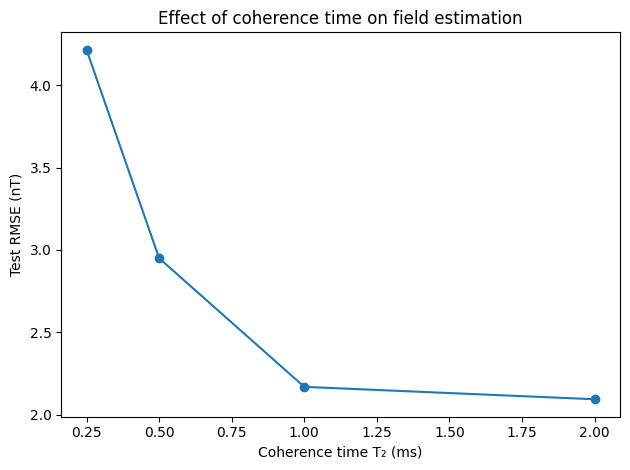

In [11]:
plt.plot(T2_results["T2_ms"], T2_results["RMSE"], marker="o")
plt.xlabel("Coherence time T₂ (ms)")
plt.ylabel("Test RMSE (nT)")
plt.title("Effect of coherence time on field estimation")
plt.tight_layout()
plt.show()

The coherence envelope is ${e^{-t/T_2}}$. This plot illustrates how the visibility changes with interrogation time for the coherence times considered above.

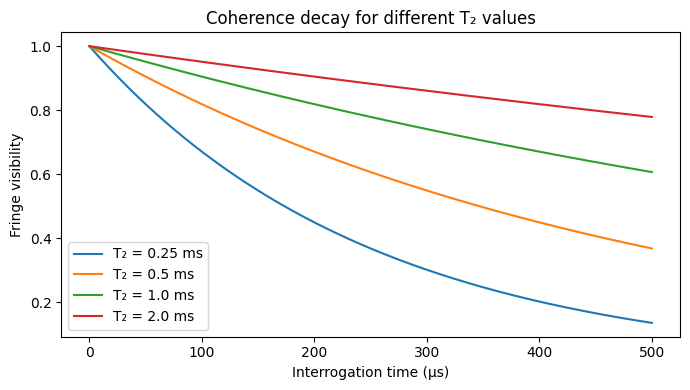

In [12]:
t_plot = np.linspace(0, 500e-6, 300)

plt.figure(figsize=(7, 4))
for T2_ms in T2_values_ms:
    visibility = np.exp(-t_plot / (T2_ms * 1e-3))
    plt.plot(t_plot * 1e6, visibility, label=f"T₂ = {T2_ms} ms")

plt.xlabel("Interrogation time (μs)")
plt.ylabel("Fringe visibility")
plt.title("Coherence decay for different T₂ values")
plt.legend()
plt.tight_layout()
plt.show()

The simulations show how finite-shot fluctuations and decoherence affect the information available to the estimator.The Random Forest is retrained for each simulated condition, so these experiments measure performance under each assumed data-generating model. They do not test robustness to an unknown mismatch between the training model and a real sensor.